### Valentin Lorenzo Carroza Granifo 22.437.518-2

In [5]:
import numpy as np # Importa la biblioteca numpy al codigo
import matplotlib.pyplot as plt # importa la biblioteca matplotlib al codigo
import pandas as pd # Importa la biblioteca pandas al codigo

In [6]:
rng = np.random.default_rng(seed=2000)

# Problema 1

### Parte 1

In [7]:
n = 100 # Variable del numero de estreallas
radio = rng.uniform(0.5, 5, n) # Genera radios solares de 0,5 a 5
distancia = rng.uniform(50, 500, n) # Genera distancias desde los 50 a 500 parcesc
temperatura = rng.uniform(3000, 10000, n) # Genera temperaturas desde los 3000 a 10000 Kelvin

In [8]:
ids = [f"E{i}" for i in range(1, n+ 1 )] # Asigna un id a cada estrella 

In [9]:
# Crea el catalogo con todos los datos
catalogo = pd.DataFrame({
    "ID": ids,
    "Radio (R_sol)": radio,
    "Distancia (PC)": distancia, 
    "Temperatura (K)": temperatura
}) 

In [10]:
catalogo.head(10)

,ID,Radio (R_sol),Distancia (PC),Temperatura (K)
0,E1,3.088113,170.057289,9620.592889
1,E2,3.453911,372.406846,8312.642056
2,E3,0.621670,217.184442,7867.648751
3,E4,2.779508,236.425933,6490.689870
4,E5,3.412258,415.498551,5058.196536
5,E6,1.710728,265.786351,5376.870411
6,E7,4.826562,89.372810,7144.722474
7,E8,2.345515,309.980413,8317.623064
8,E9,2.908692,391.630418,6898.968987
9,E10,0.779126,311.684243,4447.978996


In [11]:
catalogo.describe() # Estadisitcas descriptivas

,Radio (R_sol),Distancia (PC),Temperatura (K)
count,100.000000,100.000000,100.000000
mean,2.688238,262.184234,6669.691147
std,1.244282,123.941286,1958.561576
min,0.510142,52.498271,3011.691528
25%,1.658575,160.769305,5244.448740
50%,2.793796,267.752670,6686.303386
75%,3.671034,368.588684,8049.545438
max,4.826562,492.962827,9957.519445


### Parte 2

In [21]:
sb = 5.67037e-8 # constante de Stefan-Boltzmann
R_sol = 6.957e8 # radio solar
L_sol = 3.828e26 # luminosidad solar nominal
pc = 3.0857e16 # 1 parsec

In [22]:
r_m = catalogo["Radio (R_sol)"] * R_sol # Radios solares en metros
d_m = catalogo["Distancia (PC)"] * pc # Distancias en metros
t = catalogo["Temperatura (K)"]

In [27]:
L_W = 4 * np.pi * r_m**2 * sb * t**4 # luminosidad en Watts
L_Lsol = L_W / L_sol # luminosidad en Luinosidades solares.

In [30]:
F = L_W / (4 * np.pi * d_m**2) # Flujo en W m^-2

In [34]:
catalogo["Luminosidad (L_sol)"] = L_Lsol # Agrega las luminosidades al catalogo
catalogo["Flujo (W m^-2)"] = F # Agrega los flujos al catalogo
catalogo

,ID,Radio (R_sol),Distancia (PC),Temperatura (K),Luminosidad (L_sol),Flujo (W m^-2)
0,E1,3.088113,170.057289,9620.592889,73.601587,8.142380e-11
1,E2,3.453911,372.406846,8312.642056,51.318255,1.183835e-11
2,E3,0.621670,217.184442,7867.648751,1.334113,9.048775e-13
3,E4,2.779508,236.425933,6490.689870,12.353570,7.070611e-12
4,E5,3.412258,415.498551,5058.196536,6.866887,1.272552e-12
...,...,...,...,...,...,...
95,E96,3.071260,269.718989,4733.157867,4.265111,1.875694e-12
96,E97,4.744958,146.775808,5482.838795,18.330739,2.722235e-11
97,E98,1.809212,356.257977,4155.430501,0.879299,2.216471e-13
98,E99,3.579204,402.900115,5778.747120,12.870663,2.536652e-12


In [53]:
i_Lmax = catalogo["Luminosidad (L_sol)"].idxmax() # Identifica el id de luminosidad maxima
i_Lmin = catalogo["Luminosidad (L_sol)"].idxmin() # Identifica el id de luminosidad minima
i_Fmax = catalogo["Flujo (W m^-2)"].idxmax() # Identifica el id del flujo maximo
i_Fmin = catalogo["Flujo (W m^-2)"].idxmin() # Identifica el id del dlujo maximo

In [54]:
 # Imprime los valores maximos y minimos
print(f"Mayor luminosidad: {catalogo.loc[i_Lmax, 'ID']} -> {catalogo.loc[i_Lmax, col_L]:.4f} L_sol")
print(f"Menor luminosidad: {catalogo.loc[i_Lmin, 'ID']} -> {catalogo.loc[i_Lmin, col_L]:.4f} L_sol")
print(f"Mayor flujo: {catalogo.loc[i_Fmax, 'ID']} -> {catalogo.loc[i_Fmax, col_F]} W/m^2")
print(f"Menor flujo: {catalogo.loc[i_Fmin, 'ID']} -> {catalogo.loc[i_Fmin, col_F]} W/m^2")

Mayor luminosidad: E78 -> 162.5988 L_sol
Menor luminosidad: E89 -> 0.0597 L_sol
Mayor flujo: E84 -> 7.624047648777891e-10 W/m^2
Menor flujo: E89 -> 1.8874883312981032e-14 W/m^2


### Parte 3

In [55]:
f_lim = 2e-10 # Flujo limite

In [71]:
# Evalua la condicion para todas las filas, y crea la columna "Clasificacion"
catalogo["Clasificacion"] = np.where(catalogo["Flujo (W m^-2)"] >= f_lim, "Detectada", "No detectada") 

In [72]:
catalogo["Clasificacion"].value_counts() # Cuantas estrellas son detectadas y no detectadas

Clasificacion
No detectada    94
Detectada        6
Name: count, dtype: int64

In [67]:
100 * (catalogo["Clasificacion"] == "Detectada").mean() # porcentaje de estrellas detectadas

np.float64(6.0)

In [76]:
catalogo.groupby("Clasificacion")[["Flujo (W m^-2)", "Distancia (PC)", "Temperatura (K)"]].mean()

,Flujo (W m^-2),Distancia (PC),Temperatura (K)
Clasificacion,,,
Detectada,3.896869e-10,76.682944,9049.768732
No detectada,1.794581e-11,274.024742,6517.771301


In [113]:
# Asigna nombres mas compactos a cada columna
col_R = "Radio (R_sol)"
col_d = "Distancia (PC)"
col_T = "Temperatura (K)"
col_L = "Luminosidad (L_sol)"
col_F = "Flujo (W m^-2)"

Text(0, 0.5, 'Número de estrellas')

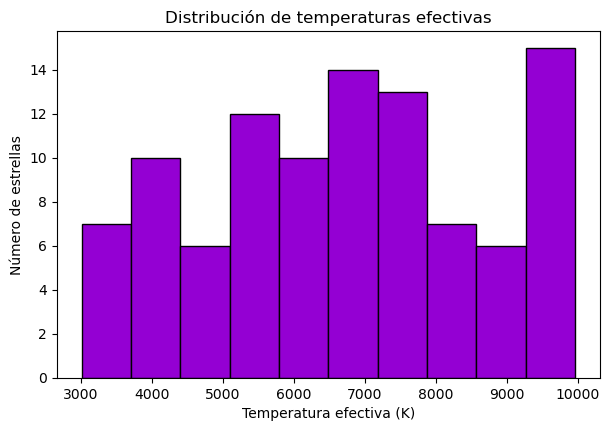

In [114]:
# Temperaturas efectivas
plt.figure(figsize=(7, 4.5)) # Determina el tamaño de la figura
plt.hist(catalogo[col_T], color="darkviolet", edgecolor="black") # Crea el histograma
plt.title("Distribución de temperaturas efectivas") # Pone ttitulo al histograma
plt.xlabel("Temperatura efectiva (K)") # Nombra el eje x
plt.ylabel("Número de estrellas") # Nombra el eje y

Text(0, 0.5, 'Número de estrellas')

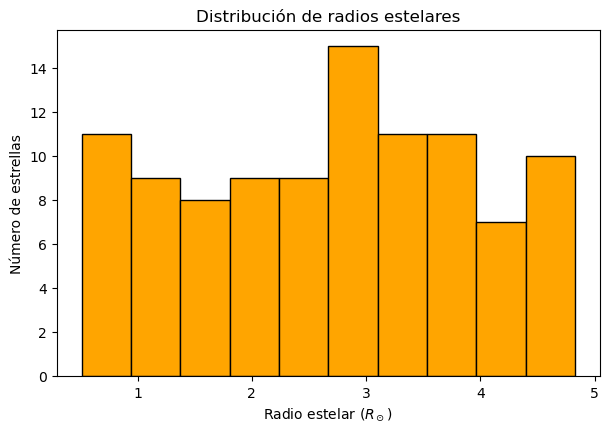

In [115]:
# Radios estelares
plt.figure(figsize=(7, 4.5)) # Determina el tamaño de la figura
plt.hist(catalogo[col_R], color="orange", edgecolor="black") # Crea el histograma
plt.title("Distribución de radios estelares") # Pone ttitulo al histograma
plt.xlabel(r"Radio estelar ($R_\odot$)") # Nombra el eje x
plt.ylabel("Número de estrellas") # Nombra el eje y

Text(0, 0.5, 'Número de estrellas')

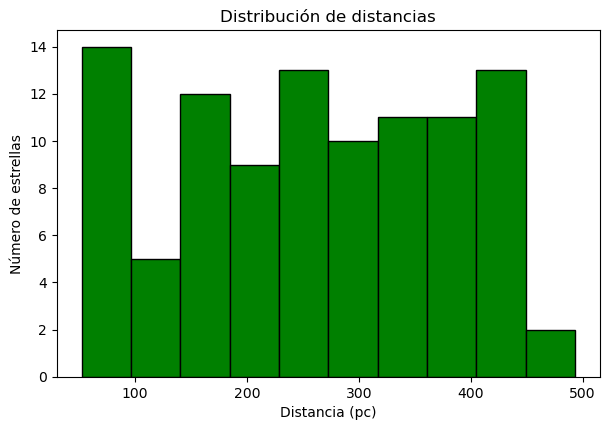

In [118]:
# Distancias
plt.figure(figsize=(7, 4.5)) # Determina el tamaño de la figura
plt.hist(catalogo[col_d], color="green", edgecolor="black") # Crea el histograma
plt.title("Distribución de distancias") # Pone ttitulo al histograma
plt.xlabel("Distancia (pc)") # Nombra el eje x
plt.ylabel("Número de estrellas") # Nombra el eje y

Text(0, 0.5, 'Número de estrellas')

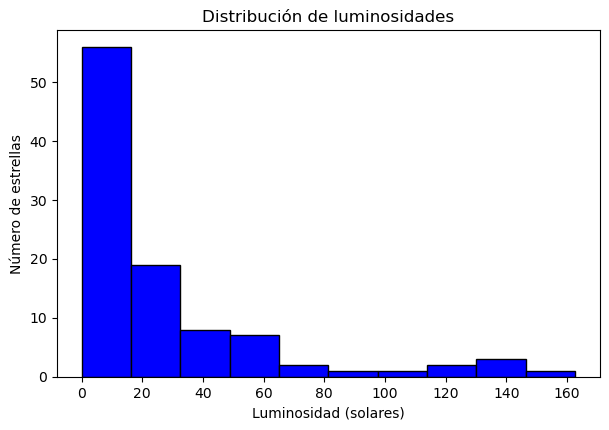

In [131]:
# (d) Luminosidades
plt.figure(figsize=(7, 4.5))
plt.hist(catalogo[col_L], color="blue", edgecolor="black")
plt.title("Distribución de luminosidades")
plt.xlabel("Luminosidad (solares)")
plt.ylabel("Número de estrellas")

Text(0, 0.5, 'Número de estrellas')

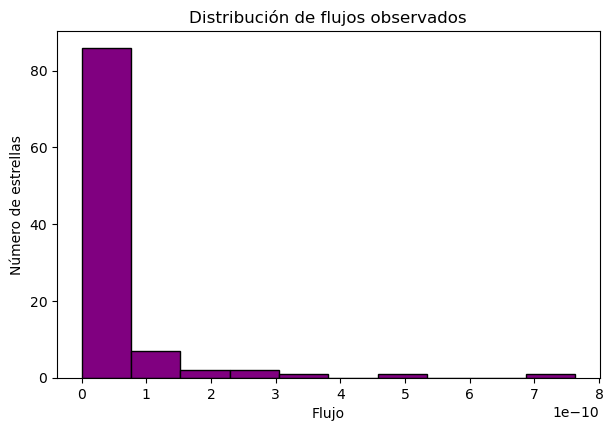

In [132]:
# Flujos
plt.figure(figsize=(7, 4.5))
plt.hist(catalogo[col_F], color="purple", edgecolor="black")
plt.title("Distribución de flujos observados")
plt.xlabel("Flujo")
plt.ylabel("Número de estrellas")

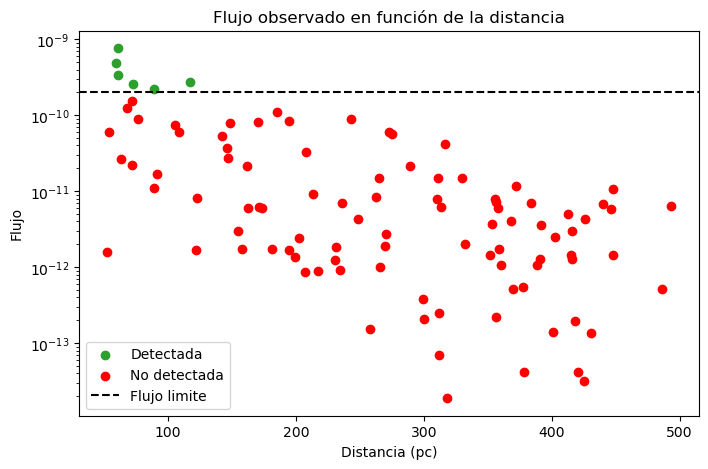

In [151]:
# Dispersion del flujo
det = catalogo[catalogo["Clasificacion"] == "Detectada"] # Asigna a las estrellas detectadas el nombre det
no_det = catalogo[catalogo["Clasificacion"] == "No detectada"] # Asigna a las estrellas no detectadas el nombre no_det
plt.figure(figsize=(8, 5)) # Asigna tamaño al grafico
plt.scatter(det[col_d], det[col_F], color="tab:green", label="Detectada") # Muestra el flujo de las estrellas
plt.scatter(no_det[col_d], no_det[col_F], color="red", label="No detectada") # Muestra las distancias entre las estrellas en parcecs
plt.axhline(f_lim, color="black", linestyle="--", label=r"Flujo limite") # Crea la linea de horizontal en limite de deteccion
plt.yscale("log") # Define en escala logaritmica el eje Y
plt.title("Flujo observado en función de la distancia") # Titula el grafico
plt.xlabel("Distancia (pc)") # Nombra el eje x
plt.ylabel("Flujo") # Nombra el eje Y
plt.legend()  # Imprime el indice

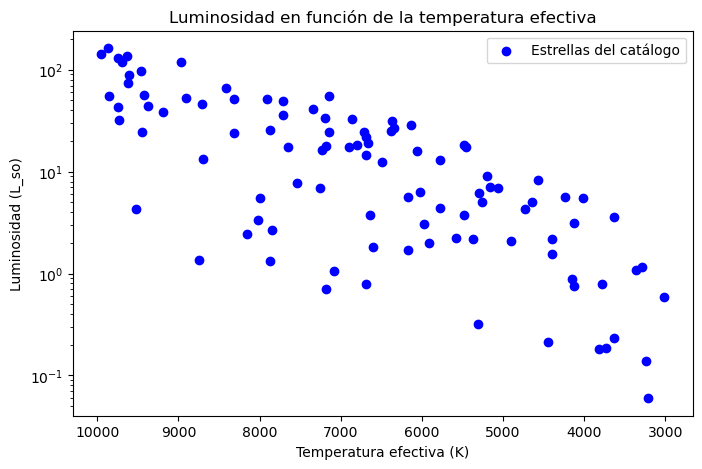

In [152]:
# Dipserion de las luminosidad
plt.figure(figsize=(8, 5))
plt.scatter(catalogo[col_T], catalogo[col_L], color="blue", label="Estrellas del catálogo")
plt.yscale("log")
plt.gca().invert_xaxis() # Reordena el eje de temperaturas de mayor a menor
plt.title("Luminosidad en función de la temperatura efectiva")
plt.xlabel("Temperatura efectiva (K)")
plt.ylabel("Luminosidad (L_so)")
plt.legend()
plt.show()